In [1]:
import datetime, os
import numpy as np
import torch
import torch.nn.functional as F

import importlib

import matplotlib.pyplot as plt

In [3]:
import data_aosi, data_s1burst
importlib.reload(data_aosi); importlib.reload(data_s1burst)

#s1_ds = data_s1burst.DataStack('greenland22.hdf5', gsi=64, device='cuda')
#s1_ds.build(data_dir='/mnt/d/S1Burst_Greenland_2022Jul2Jan')
s1_ds = data_s1burst.DataStack('svalbard23.hdf5', gsi=64, device='cuda')
#s1_ds.build(data_dir='/mnt/d/S1Burst_Svalbard_2023_Jan2Jul')
#s1_ds.coreg_stack()
data, labels, xyz = s1_ds.read(0)
print(labels, data.shape, datetime.datetime.fromtimestamp(data[...,2].real.mean().int()))

if False:  #  set to "True" to view contents of DataStack
    for i in range(len(s1_ds.h5f['scenes'])):
        key = list(s1_ds.h5f['scenes'].keys())[i]
        for j in range(len(s1_ds.h5f['scenes'][key]['b'])):
            key2 = list(s1_ds.h5f['scenes'][key]['b'].keys())[j]
            tmp = s1_ds.h5f['scenes'][key]['b'][key2]['data'][::8,::8]
            plt.imshow(np.abs(tmp), aspect=10);
            plt.show()
del(data, labels)

dates = [datetime.datetime.strptime(el, '%Y%m%dT%H%M%S') for el in s1_ds.h5f['scenes'].keys()]

llh = np.stack(data_aosi.wgs84_xyz2llh(*(xyz.view(-1,3).T.cpu().numpy())), axis=0)
latb, lonb = (llh[0].min(), llh[0].max()), (llh[1].min(), llh[1].max()); print(latb, lonb)
aosi_ds = data_aosi.Dataset(fn_id='current', variables=['sithick'], latb=latb, lonb=lonb, device='cuda')
#aosi_ds.download_data(dates)

# -- access check
#for key, item in aosi_ds.h5f['scenes'].items():
#    print(item['var_sithick'])
#    plt.imshow(item['var_sithick'][()]); plt.show()

# -- secondary check
#sit_mini = aosi_ds.read_at(xyz, dates)
#for i in range(sit_mini.shape[0]):
#    plt.imshow(sit_mini[i,0].cpu().numpy())
#    plt.show()

['HH_rast1', 'HV_rast1', 'az_t', 'sr_t', 'ia', 'ea'] torch.Size([1520, 23516, 6]) 2023-01-04 15:45:20
(np.float32(80.01243), np.float32(80.39613)) (np.float32(14.534585), np.float32(18.817368))


INFO - 2026-06-12T11:19:53Z - Selected dataset version: "202311"
INFO - 2026-06-12T11:19:53Z - Selected dataset part: "default"
INFO - 2026-06-12T11:19:56Z - Starting download. Please wait...
INFO - 2026-06-12T11:19:58Z - Successfully downloaded to working_cache_aosi/tmp.nc
INFO - 2026-06-12T11:20:04Z - Selected dataset version: "202311"
INFO - 2026-06-12T11:20:04Z - Selected dataset part: "default"
INFO - 2026-06-12T11:20:07Z - Starting download. Please wait...
INFO - 2026-06-12T11:20:08Z - Successfully downloaded to working_cache_aosi/tmp.nc
INFO - 2026-06-12T11:20:13Z - Selected dataset version: "202311"
INFO - 2026-06-12T11:20:13Z - Selected dataset part: "default"
INFO - 2026-06-12T11:20:16Z - Starting download. Please wait...
INFO - 2026-06-12T11:20:18Z - Successfully downloaded to working_cache_aosi/tmp.nc
INFO - 2026-06-12T11:20:22Z - Selected dataset version: "202311"
INFO - 2026-06-12T11:20:22Z - Selected dataset part: "default"
INFO - 2026-06-12T11:20:25Z - Starting download

In [4]:
import brack2bing, data_resice
if (os.path.exists("brack2bing_solver_cache/init.pickle")):
    icesim = brack2bing.LatticeSolver.load()
else:
    icesim = brack2bing.LatticeSolver(device='cuda')
    icesim.save()
T,S,rho = data_resice.get_scaled_cores(bins=125, device='cuda', min_samples=4, max_depth=2.5)
lattice = icesim.gen_lattice(T,S,rho, hshape=(150,25))
er = icesim.get_dielectric(lattice, T, 1.2)

import crefl2slc; importlib.reload(crefl2slc)
if (os.path.exists('SimpleReflector_Sentinel1_latest.pickle')):
    sref = crefl2slc.SimpleReflector.load('SimpleReflector_Sentinel1_latest.pickle')
else:
    sref = crefl2slc.SimpleReflector(er, T, cells_per_m=200, wavelength_m=0.05547, batch_size=4)
    print('floquet incidence modes:', np.round(np.rad2deg(sref.ia_input)[:,0], decimals=2))
    sref.gen_refl_sample(ia_b=(30,50)) # typical sentinel-1 incidence angle
    srefi.gen_refl_spline()
    sref.save('SimpleReflector_Sentinel1_latest.pickle')

In [6]:
import util_filters
def invert(slc, ia, rg, srefi, T=None, iters=50, scale0=50, verbose=True):
    c_slc = torch.as_tensor(slc, device=srefi.device, dtype=torch.complex64)
    #c_slc /= torch.max(torch.abs(c_slc)) # normalize magnitude
    c_ia = torch.as_tensor(ia, device=srefi.device, dtype=srefi.dtype)
    c_rg = torch.as_tensor(rg, device=srefi.device, dtype=srefi.dtype)
    
    p_thc = torch.ones_like(c_slc[0], dtype=srefi.dtype, requires_grad=True)
    p_scale = torch.tensor([scale0], device=srefi.device, dtype=srefi.dtype, requires_grad=True) # rescale offset
    if T is None:
        p_T = torch.tensor([[-2.5]], device=srefi.device, dtype=srefi.dtype, requires_grad=True)
        params = [p_thc, p_scale, p_T]
    else:
        p_T = torch.tensor([[T]], device=srefi.device, dtype=srefi.dtype, requires_grad=True)
        params = [p_thc, p_scale, p_T]
    
    optimizer = torch.optim.AdamW(params, lr=0.1)
    #scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=50)
    for i in range(iters):
        optimizer.zero_grad()
        with torch.no_grad():
            p_thc.clamp_(min=0)
        p_slc = srefi.slc_simulate(p_thc, c_rg, c_ia, p_T.expand(p_thc.shape), F.relu(p_scale)**2).permute(2,0,1)[:2]
        loss = ((p_slc - c_slc)**2).abs().mean() + ((p_slc.abs() - c_slc.abs())**2).mean()
        loss += (((p_slc[1].abs()/(0.1+p_slc[0].abs())) - (c_slc[1].abs()/(0.1+c_slc[0].abs())))**2).mean() #polarimetric ratio
        #loss += 0.2 * ((p_thc[1:,:-1] - p_thc[:-1,:-1])**2 + (p_thc[:-1,1:] - p_thc[:-1,:-1])**2).mean() # TV loss
        #loss += torch.exp(-100*p_thc).sum() # clamp to positive value
        if verbose : print(i, loss.item(), 'T_est:', p_T.item(), p_scale.item())
        loss.backward()
        optimizer.step()
        #scheduler.step()

    return p_thc.detach(), p_slc.detach()

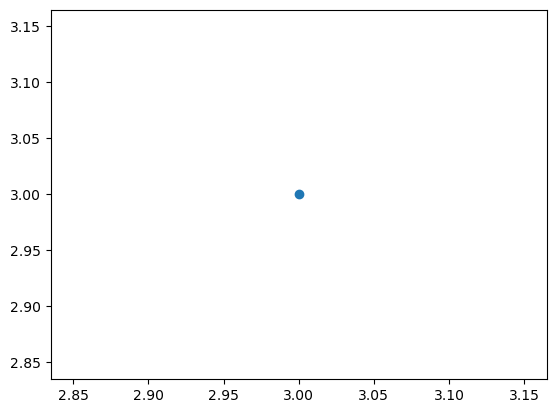

In [10]:
plt.scatter([3],[3])
plt.savefig('img_dump/example.png')
plt.show()

temperature:  -1.0


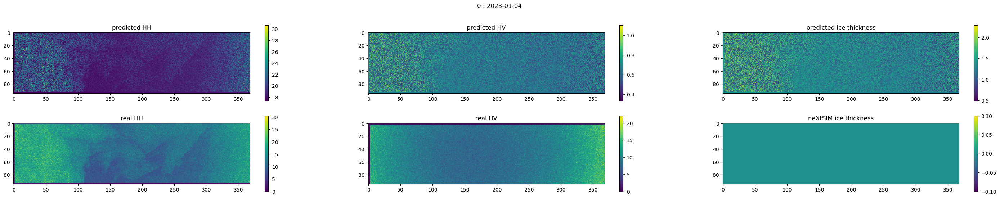

temperature:  -9.9


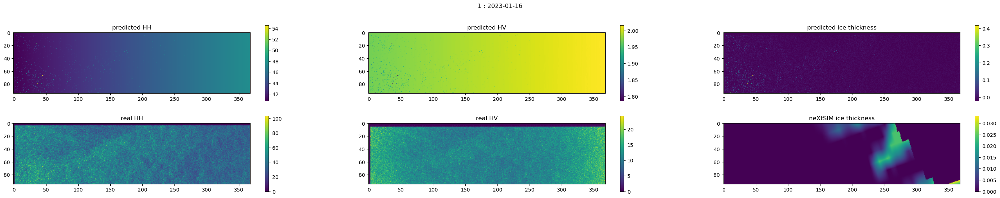

temperature:  -6.9


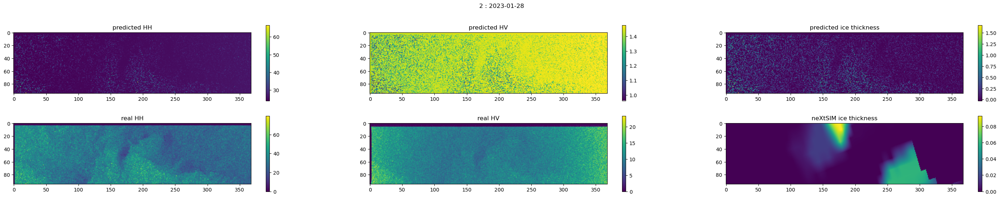

temperature:  -1.8


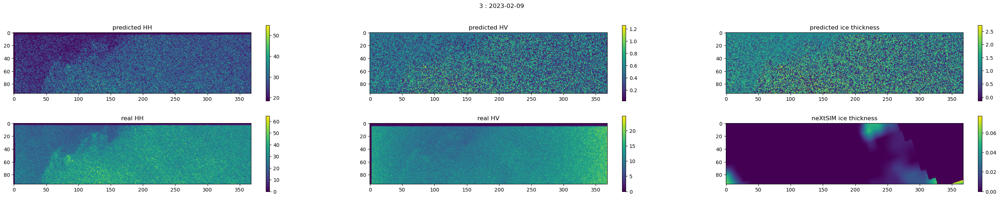

temperature:  -3.8


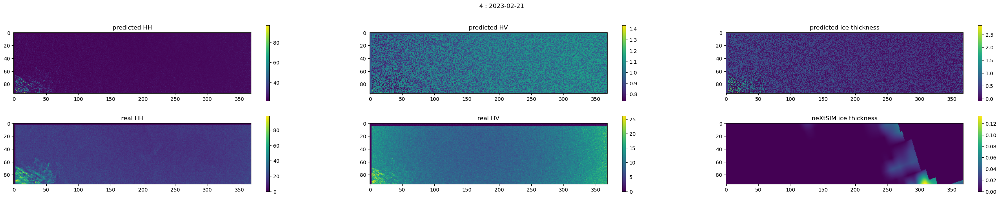

temperature:  -13.4


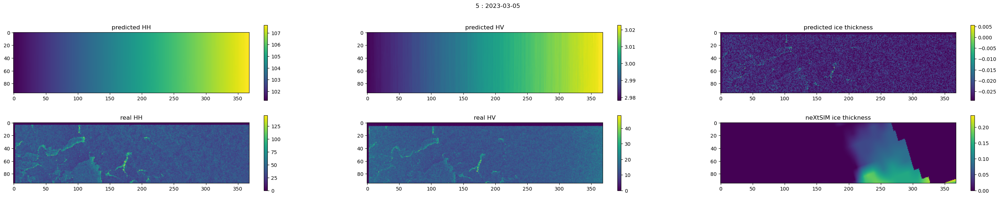

temperature:  -14.2


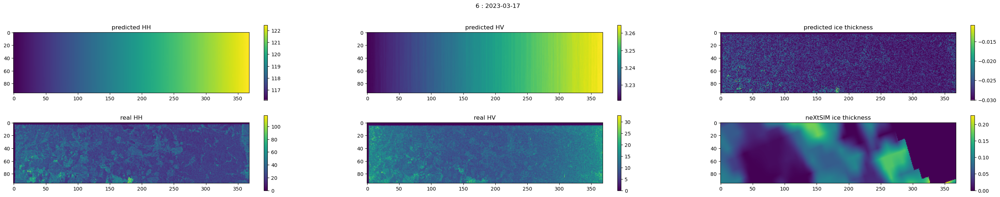

temperature:  -10.1


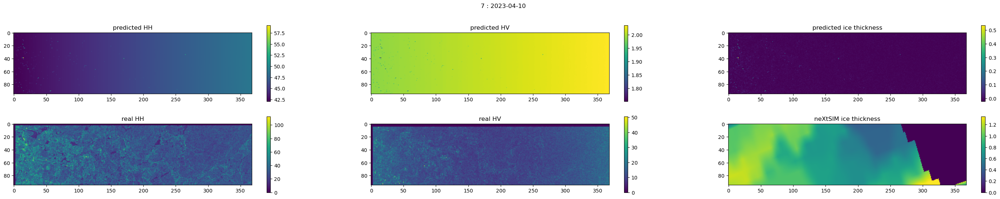

temperature:  -14.0


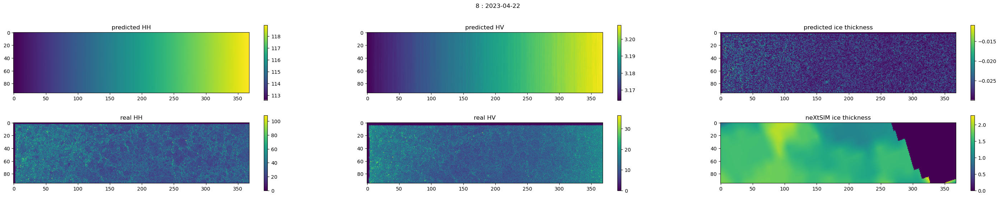

temperature:  -6.8


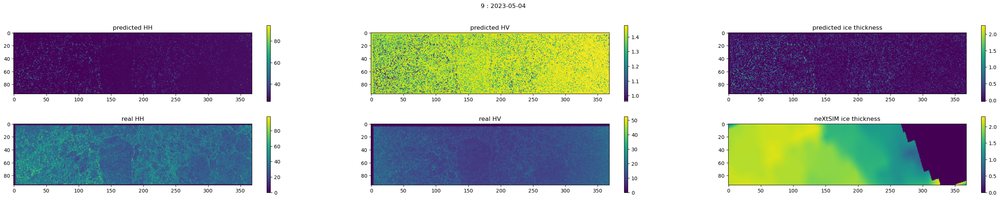

temperature:  -7.8


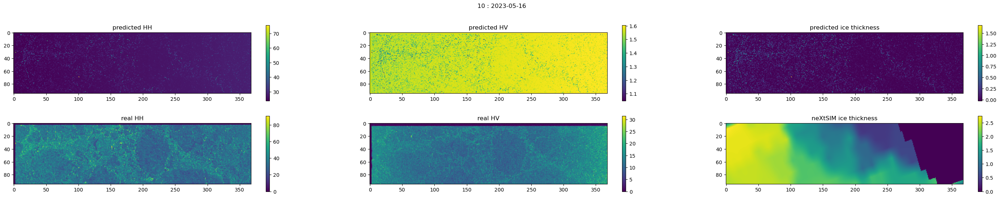

temperature:  -2.4


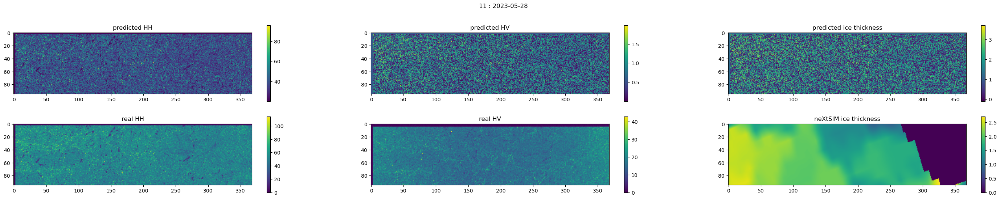

temperature:  0.4


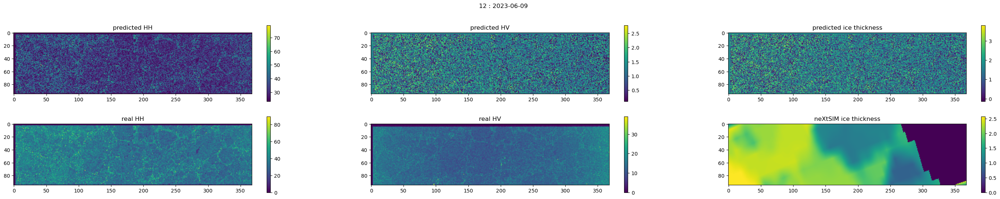

temperature:  2.4


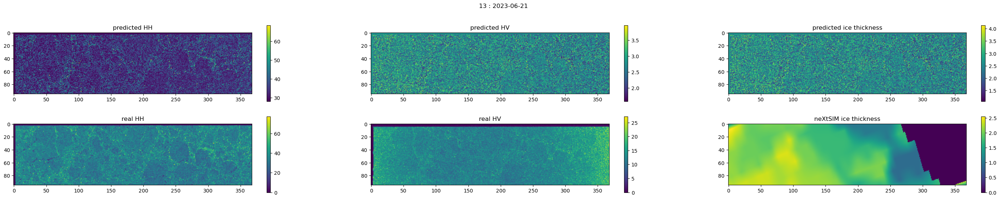

In [13]:
import data_meteo
tkl = []

spi, spj = 16, 64
for i in range(len(dates)):
    #if i > 0 : break
    data, labels, xyz = s1_ds.read(i)

    tdelta = datetime.timedelta(hours=1)
    lat, lon = np.stack(data_aosi.wgs84_xyz2llh(*(xyz[::spi,::spj].reshape(-1,3).T.cpu().numpy())), axis=0).mean(axis=-1)[:2]
    tdf = data_meteo.get_temperatures(lat, lon, dates[i]-tdelta, dates[i]+tdelta)
    T = tdf.iloc[np.argmin(tdf['time'] - dates[i])]['temperature_2m'].item()
    print('temperature: ', T)
    slc = data[:,:,:2].moveaxis(-1,0)
    slc = util_filters.lee_filter(slc[None].abs(), window_size=7)[0] * torch.exp(1j*slc.angle())
    slc = slc[:,11::spi,11::spj]
    ia = torch.deg2rad(data[::spi,::spj, labels.index('ia')].real)
    rg = data[::spi,::spj, labels.index('sr_t')].real * 299792458
    p_data = invert(slc, ia, rg, sref, T, iters=100, scale0=30, verbose=False)

    sit_ref = aosi_ds.read_at(xyz[::spi,::spj], [dates[i],]).cpu()[0,0]
    sit_ref[torch.isnan(sit_ref)] = 0

    plt.figure(figsize=(36,6));
    plt.subplot(2,3,1); plt.imshow(p_data[1][0].cpu().abs()); plt.colorbar(); plt.title('predicted HH')
    plt.subplot(2,3,4); plt.imshow(slc[0].cpu().abs()); plt.colorbar(); plt.title('real HH')
    
    plt.subplot(2,3,2); plt.imshow(p_data[1][1].cpu().abs()); plt.colorbar(); plt.title('predicted HV')
    plt.subplot(2,3,5); plt.imshow(slc[1].cpu().abs()); plt.colorbar(); plt.title('real HV')
    
    plt.subplot(2,3,3); plt.imshow(p_data[0].cpu()); plt.colorbar(); plt.title('predicted ice thickness')
    plt.subplot(2,3,6); plt.imshow(sit_ref); plt.colorbar(); plt.title('neXtSIM ice thickness')

    label = str(i) + ' : ' + dates[i].strftime('%Y-%m-%d')
    plt.suptitle(label)

    plt.savefig(f'img_dump/{label}.png')
    plt.show()

    tkl.append(p_data[0].cpu())
    torch.cuda.empty_cache()

In [15]:
total = []
for i in range(len(tkl)):
    #plt.imshow(np.log1p(s1_ds.read(i)[0].abs()[::16,::64,0][5:,5:].cpu().numpy()), aspect=4); plt.colorbar(); plt.show()
    #sit_sim = F.max_pool2d(tkl[i][None,None,:,:].cpu(), 3)[0,0]
    sit_sim = (tkl[i][None,None,:,:].cpu())[0,0]
    #plt.imshow(sit_sim, aspect=4); plt.colorbar(); plt.show()
    sit_ref = aosi_ds.read_at(xyz[::64,::256], [dates[i],]).cpu()[0,0]
    sit_ref[torch.isnan(sit_ref)] = 0
    #plt.imshow(sit_ref, aspect=4); plt.colorbar(); plt.show()
    #total.append((sit_sim.nanmean(), sit_ref.nanmean()))
    #total.append((torch.histogram(sit_sim), torch.histogram(sit_ref)))
    total.append(((torch.mean(sit_sim), torch.mean(sit_ref))))
total = [el for el in zip(*total)]

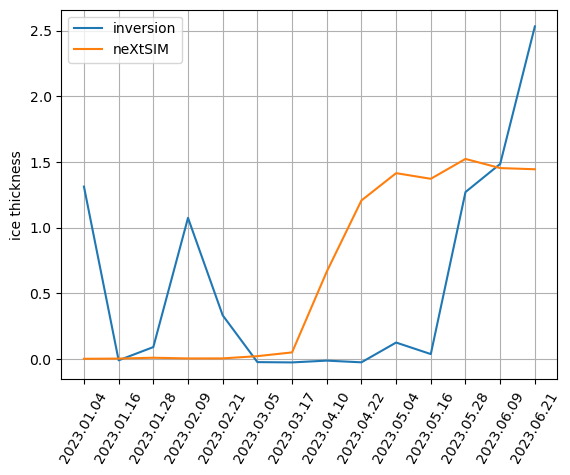

In [16]:
plt.plot(total[0]); plt.plot(total[1]);
plt.xticks(np.arange(len(dates)), [date.strftime('%Y.%m.%d') for date in dates], rotation=60)
plt.ylabel('ice thickness')
plt.grid(True)
plt.legend(['inversion', 'neXtSIM'])
plt.show()